# [수업] 실습 ② 요약 생성 — 텍스트·표·이미지를 검색 가능한 요약문으로


지난 시간에 PDF에서 꺼낸 **텍스트 / 표 / 이미지**를, 검색에 쓸 수 있는 **요약문(색인 카드)** 으로 바꿉니다.

```
텍스트 ──┐
  표   ──┼──▶  요약문 생성  ──▶  검색용 색인(색인 카드)
이미지 ──┘      LLM / VLM
```

## 수업 진행 방식

- 코드 셀에는 **주석만** 있습니다. 강사 화면을 보며 주석 아래에 코드를 **함께 작성**합니다.
- 각 단계마다 **📖 개념 → ⌨️ 따라 치기 → ✅ 확인** 순서로 진행합니다.
- 셀은 위에서부터 순서대로 실행합니다 (`Shift + Enter`).

## 오늘의 학습 목표

1. LCEL 파이프(`|`)로 **요약 체인**을 구성할 수 있다
2. LLM으로 **텍스트·표 요약**을 일괄(batch) 생성할 수 있다
3. 이미지를 **Base64**로 변환해 **VLM**에 전달할 수 있다
4. 요약 품질을 **육안으로 검증**하고 비용(토큰)을 측정할 수 있다

## 💸 비용 안내

`gpt-4o-mini` 기준 PDF 한 편에 수십 원 수준입니다. 다만,
- 요약 셀을 **반복 실행하면 그만큼 비용이 다시** 나갑니다
- `max_concurrency`를 함부로 올리면 `RateLimitError`에 걸립니다

---
# Part 1. 준비

## 0. API 키 불러오기

### 📖 개념
- API 키는 `.env` 파일에 두고 `python-dotenv`로 읽어 옵니다. 코드에 직접 적지 않습니다.
- 키 전체를 `print()` 하지 않습니다. 화면 공유나 스크린샷 한 번이면 유출됩니다. **앞 7자 + 뒤 4자**만 확인합니다.

In [4]:
# ⌨️ 0-1. os, time, pickle, Path(pathlib), load_dotenv(dotenv) 를 임포트합니다.
import os
import time
import pickle
from pathlib import Path
from dotenv import load_dotenv

# ⌨️ 0-2. PROJECT_ROOT 를 정합니다.
#        현재 폴더 이름이 "invest" 또는 "practice" 이면 상위 폴더, 아니면 현재 폴더
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name in ["invest", "practice"] else Path.cwd()

    # Path.cwd() : 현재 위치
    # Path.cwd().parent : (현재 위치 기준) 상위 폴더
    # PROJECT_ROOT : multimodal-rag 폴더

# ⌨️ 0-3. PROJECT_ROOT / ".env" 파일을 load_dotenv 로 읽습니다.
load_dotenv(PROJECT_ROOT / "..env")
    # PROJECT_ROOT / .env : multimodal-rag/.env

# ⌨️ 0-4. 환경변수 "OPENAI_API_KEY" 를 openai_api_key 에 담습니다.
openai_api_key = os.getenv("OPENAI_API_KEY")

    # os.getenv : 환경변수에서 값을 가져오는 함수
    # openai_api_key -> 공용 변수로 처리하겠다



# ⌨️ 0-5. 키가 없으면 ValueError 를 발생시킵니다.
if not openai_api_key:
    raise ValueError("환경변수 OPENAI_API_KEY가 없습니다. .env 파일을 확인하세요.")


# ⌨️ 0-6. 키를 "앞 7자 + ... + 뒤 4자" 형태로만 출력합니다.
print(f"API KEY : {openai_api_key[:7]} + ... + {openai_api_key[-4:]}")


API KEY : sk-proj + ... + Vq0A


In [5]:
# ⌨️ 0-7. 키가 실제로 유효한지 확인합니다.
#        openai 패키지에서 OpenAI, AuthenticationError 를 임포트하고
#        OpenAI().models.list() 를 호출해 AuthenticationError 가 나면 안내 문구와 함께 중단합니다.
from openai import AuthenticationError, OpenAI


# 통상적인 예외처리 -> try...except 구문 사용
# api_key=openai_api_key : 정의한 openai_api_key를 api_key 매개변수에 지정
try:
    OpenAI(api_key=openai_api_key).models.list()
except AuthenticationError:
    raise ValueError(f"환경변수 OPENAI_API_KEY가 유효하지 않습니다. .env 파일을 확인하세요. (API KEY : {openai_api_key[:7]} + ... + {openai_api_key[-4:]})")

> ✅ **확인:** `API 키 로드 완료: sk-proj...abcd` 형태로 출력되고, 유효성 확인에서 오류가 없어야 합니다.

## 1. 지난 시간 결과 복원

### 📖 개념
- PDF 추출(`hi_res`)은 2~3분이 걸립니다. 그래서 지난 시간 마지막에 **pickle**로 저장해 두었습니다.
- pickle = 파이썬 객체를 그대로 **냉동 보관**했다가 **해동**해서 쓰는 도구입니다.
- `FileNotFoundError`가 나면 지난 시간 노트북의 **저장 셀**을 실행하지 않은 것입니다.

In [ ]:
# ⌨️ 1-1. PROJECT_ROOT / "data" / "processed" / "extracted.pkl" 경로를 pkl_path 에 담습니다.

pkl_path = PROJECT_ROOT / "data" / "processed" / "extracted.pkl"
    # pkl_path : multimodal-rag/data/processed/extracted.pkl -> extracted.pkl 파일 경로
# ⌨️ 1-2. 파일을 바이너리 읽기 모드("rb")로 열어 pickle.load 로 data 에 불러옵니다.

with open(pkl_path, "rb") as f:
    data = pickle.load(f)
    # "rb" : 바이너리 읽기 모드
    # pickle.load(f) : pickle 파일을 읽어 -> Python 객체로 되살리기
    
    ### load() vs dump() ### 
    # load()는 파일에서 객체를 읽어오는 것, dump()는 객체를 파일에 저장하는 것


# ⌨️ 1-3. data 딕셔너리에서 texts, tables, texts_2k_token 을 꺼냅니다.
texts = data["texts"]
tables = data["tables"]
texts_2k_token = data["texts_2k_token"]

# ⌨️ 1-4. 각 리스트의 개수를 출력합니다.
print("texts 개수:", len(texts))
print("tables 개수:", len(tables))
print("texts_2k_token 개수:", len(texts_2k_token))


# ⌨️ 1-5. 지난 시간에 이미지를 저장한 폴더를 figures_dir 로 잡고 존재 여부를 출력합니다.
#        (지난 시간: PDF 폴더 아래 "figures" → PROJECT_ROOT / "data" / "figures")
figures_dir = PROJECT_ROOT / "data" / "figures"
print("존재:", figures_dir.exists())


> ✅ **확인:** 세 리스트 개수가 지난 시간과 같고, 이미지 폴더 `존재: True` 여야 합니다. `False`면 본인 PDF 폴더 이름에 맞게 경로를 고칩니다.

---
# Part 2. 텍스트·표 요약 (LLM)

## 2. 요약 체인 만들기

### 📖 개념 — LCEL 파이프는 컨베이어 벨트
왼쪽 작업대의 결과물이 오른쪽 작업대의 재료가 됩니다.

```
{"element": lambda x: x}  →  prompt  →  model  →  StrOutputParser()
       입력 포장              템플릿 적용   LLM 호출      문자열로 꺼내기
```

| 칸 | 받는 것 | 내보내는 것 |
| --- | --- | --- |
| `{"element": lambda x: x}` | 문자열 | `{"element": 문자열}` 딕셔너리 |
| `prompt` | 딕셔너리 | 완성된 프롬프트 |
| `model` | 프롬프트 | `AIMessage` 객체 |
| `StrOutputParser()` | `AIMessage` | 순수 문자열 |

### 📖 개념 — `.batch()` 와 `max_concurrency`
- `.invoke(x)` 는 한 건, `.batch([x1, x2, ...])` 는 여러 건을 **동시에** 처리합니다.
- `max_concurrency=5` → 동시에 최대 5건만 요청. 너무 높이면 `RateLimitError`.
- `temperature=0` → 같은 입력에 최대한 같은 출력 (요약은 창의성보다 **일관성**이 중요)

In [7]:
# ⌨️ 2-1. StrOutputParser, ChatPromptTemplate, ChatOpenAI 를 임포트합니다.
#        (langchain_core.output_parsers / langchain_core.prompts / langchain_openai)

from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI

# ⌨️ 2-2. generate_text_summaries(texts, tables, summarize_texts=False) 함수를 정의합니다.

def generate_text_summaries(texts, tables, summarize_texts=False):
    
#   ⌨️ (1) 한국어 요약 프롬프트 문자열을 작성합니다. 반드시 {element} 자리표시자를 포함합니다.
#          내용: "표와 텍스트를 검색용으로 요약하는 도우미 / 임베딩되어 원본 검색에 쓰임 /
#                 검색에 최적화된 간결한 요약 작성 / 요약할 표 또는 텍스트: {element}"

    prompt_template_kor = """
                    표와 텍스트를 검색용으로 요약하는 도우미 / 임베딩되어 원본 검색에 쓰임 /
                    검색에 최적화된 간결한 요약 작성 / 요약할 표 또는 텍스트: {element}"""
                

    prompt_template_eng = """
                    You are an assistant tasked with summarizing tables and text for retrieval.
                    These summaries will be embedded and used to retrieve the raw text or table elements.
                    Give a concise summary of the table or text that is well optimized for retrieval.
                    Table or text: {element}"""      
                 
#   ⌨️ (2) ChatPromptTemplate.from_template 으로 prompt 를 만듭니다.

    prompt = ChatPromptTemplate.from_template(prompt_template_kor)

#   ⌨️ (3) ChatOpenAI 로 model 을 만듭니다. (temperature=0, model="gpt-4o-mini")

    model = ChatOpenAI(
        temperature=0,
        model = "gpt-4o-mini"
    )

#   ⌨️ (4) 컨베이어 벨트 4칸을 | 로 연결해 summarize_chain 을 만듭니다.

    summarize_chain = prompt | model | StrOutputParser()

#   ⌨️ (5) text_summaries, table_summaries 빈 리스트를 만듭니다.

    text_summaries = []
    table_summaries = []

#   ⌨️ (6) texts 가 있고 summarize_texts 가 True 면 → batch 로 요약 (max_concurrency 5)
#          texts 는 있지만 summarize_texts 가 False 면 → 원문을 그대로 사용
    if texts and summarize_texts:
        text_summaries = summarize_chain.batch(texts, {"max_concurrency" : 5})
    elif texts and not summarize_texts:
        text_summaries = texts
    
#   ⌨️ (7) tables 가 있으면 → batch 로 요약 (max_concurrency 5)

    if tables:
        table_summaries = summarize_chain.batch(tables, {"max_concurrency" : 5})
    else:    
        table_summaries = tables

#   ⌨️ (8) text_summaries, table_summaries 를 반환합니다.

    return text_summaries, table_summaries
# ⌨️ 2-3. "generate_text_summaries 정의 완료" 를 출력합니다.

print("generate_text_summaries 정의 완료")

generate_text_summaries 정의 완료


## 3. 텍스트·표 요약 실행

> ⏱️ API 호출로 **1~3분** 걸립니다. 💸 **한 번만** 실행하세요.

In [12]:
# ⌨️ 3-1. 시작 시각을 기록합니다.

start = time.time()

# ⌨️ 3-2. texts_2k_token 과 tables 를 넣어 generate_text_summaries 를 호출합니다.
#        텍스트도 요약해야 하므로 summarize_texts=True

text_summaries, table_summaries = generate_text_summaries(texts_2k_token, tables, summarize_texts=True)

# ⌨️ 3-3. 소요 시간, 텍스트 요약 수, 표 요약 수를 출력합니다.

print(f"요약 완료 => {time.time() - start :.1f}초 걸림")
print(f"텍스트 요약 수 => {len(text_summaries)}개")
print(f"표 요약 수 => {len(table_summaries)}개")

요약 완료 => 17.3초 걸림
텍스트 요약 수 => 18개
표 요약 수 => 5개


## 4. 요약 결과 확인

### 📖 개념 — 압축률
요약문 길이 ÷ 원본 길이. 너무 높으면 요약이 안 된 것, 너무 낮으면 정보가 빠졌을 수 있습니다.

In [ ]:
# ⌨️ 4-1. 구분선과 함께 texts_2k_token[0] 의 앞 300자를 출력합니다.

print("-"*60)
print("texts_2k_token 결과:", texts_2k_token[0][:300])
print("\n\n")

# ⌨️ 4-2. 구분선과 함께 text_summaries[0] 전체를 출력합니다.

print("-"*60)
print("text_summaries 결과:", text_summaries[0])
print("\n\n")

# ⌨️ 4-3. 원본 글자 수, 요약 글자 수, 압축률(%)을 출력합니다.

original = len(texts_2k_token[0])
short = len(text_summaries[0])

print("원본 글자 수:", original)
print("요약 글자 수:", short)
print("압축률(%) :", f"{original}자 -> {short}자 (%) {short/original*100:.1f}%")



### 압축률 : 5~20% 가장 적정 (10~15% 베스트)
    # 1) 5% 미만 : 요약이 덜 됐음
    # 2) 30% 이상 : 요약 치고 내용이 많음
    
    
"""
요약길이 / 원본길이 ==> 숫자가 작을수록 더 많이 줄였다.
    1) 압축률을 낮춰주세요(10% -> 5%) => 요약을 더 짧게, 핵심만 남김
    2) 압축률을 높여주세요(5% -> 15%) => 요약을 더 길게, 세부 내용까지 남겨주세요!
"""



"""  
요약이 잘 된 기준 : 실제 질문으로 검색이 잘 되는지 정도가 높아야 함 
"""

------------------------------------------------------------
texts_2k_token 결과: 2026년 10월 22일 공보 2026-10-17호

Hote

이 자료는 배포시부터 취급하여 주십시오.

제 목 : 경제상황 평가(2026년 10월)

□ 국내경제는 중동지역 불확실성 확대에도 반도체 경기의 강한 호조세와 여타부문으로의 파급 확산 등으로 기존 전망경로를 상회하는 높은 성장세 전망

□ 물가상승률은 누적된 비용압력이 전이되고 수요압력도 점차 확대됨에 따라 높은 수준 지속 예상

□ 전망경로에는 반도체 경기, 중동상황 등과 관련한 불확실성이 큰 상황

※ 자세한 내용은 <붙 임> 경제상황 평가(2026년 10월) 참조



------------------------------------------------------------
text_summaries 결과: **경제상황 평가 요약 (2026년 10월)**

- **국내경제 전망**: 중동지역의 불확실성에도 불구하고 반도체 산업의 호조와 다른 부문으로의 긍정적 파급 효과로 인해 높은 성장세가 예상됨.
  
- **물가상승률**: 누적된 비용 압력과 확대되는 수요 압력으로 인해 물가상승률이 높은 수준을 지속할 것으로 보임.

- **불확실성 요인**: 반도체 경기와 중동 상황 등 여러 불확실성이 전망에 영향을 미칠 가능성이 있음.

- **세계경제 동향**: 높은 에너지 가격에도 불구하고 AI 투자 덕분에 세계경제는 양호한 성장세를 유지할 것으로 전망됨. 세계교역은 지정학적 리스크와 통상 갈등으로 제약을 받지만, AI 인프라 투자 관련 교역은 증가할 것으로 예상됨.

- **국제유가 전망**: 중동 상황에 따라 단기적으로 변동성이 클 것으로 보이나, 중장기적으로는 공급 증가로 인해 하락할 것으로 예상됨.

- **반도체 경기**: AI 확산과 관련된 인프라 투자 덕분에 견조한 흐름을 이어갈 것으로 보이나, AI 수익화 및 투자 속도에 대한 불확실성은 여

> ✅ **확인:** 요약문이 **한국어**로 나오고 원본의 핵심을 담고 있으면 성공입니다.

## 5. `table_summaries`가 비어 있다면?

### 📖 개념
비어 있어도 **정상일 수 있습니다.** 원인은 두 가지입니다.
1. PDF의 표가 **그림으로 그려져** 있음 → 표가 아니라 이미지로 추출됨 (Part 3에서 처리)
2. 지난 시간 추출에서 `strategy="hi_res"` 누락

In [ ]:
# ⌨️ 5-1. table_summaries 가 있으면 → 개수와 첫 번째 표 요약을 출력합니다.

if table_summaries:
    

    # print(f"표 요약 => {len(table_summaries)}건 생성됨")
    # print("\n")
    # print("[표 요약 예시]")
    # print(table_summaries[0])
    
    
    # for i, summary in enumerate(table_summaries[:3]):
    #     print("="*60)
    #     print(f"[표 요약 {i+1}]")
    #     print("="*60)
    #     print(summary)
    #     print()
        
        
    # 원본 표와 함께 비교하고 싶다.
    for i, (table, summary) in enumerate(zip(tables[:5], table_summaries[:5])):
        print("="*60)
        print(f"[표 {i+1} 원본 (앞 300자)]")
        print("="*60)
        print(table[:300])
        print()
        print("="*60)
        print(f"[표 {i+1} 요약본]")
        print("="*60)
        print(summary)
        print()        
        
# ⌨️ 5-2. 비어 있으면 → 위 두 가지 원인을 점검하라는 안내 문구를 출력합니다.
else:
    print("표 요약이 비어 있습니다."
        "원인은 1. startegy = 'hi_res'"
        "2. 진짜 표인지, 그림으로 그린 표인지 확인"
        )


표 요약 => 5건 생성됨


[표 요약 예시]
**요약:**

- **경제성장**: 조사총괄팀 - 이종웅 (02-759-4202), 최영우 (4167), 추성윤 (4172)
- **세계경제**: 국제종합팀 - 김보희 (4280)
- **경상수지**: 국제무역팀 - 남석모 (4190)
- **물가**: 물가동향팀 - 원영진 (4220)
- **고용·임금**: 고용동향팀 - 선진산 (4205)
- **경제모형**: 모형전망팀 - 박병국 (4137)


**🗒️ 정리해 보기 (더블클릭해서 편집)**

- 내 PDF의 표 요약 개수:
- 비어 있다면 그 이유는:

---
# Part 3. 이미지 요약 (VLM)

**Base64**<br>
이미지를 LLM의 컨텍스트로 입력을 하려면, Base64 인코딩 과정이 필요함<br>
- Base64 인코딩 방식은 텍스트 기반 시스템에서 안전하게 사용할 수 있는 <br> 
- 64개의 ASCII 문자만을 사용하여 이진데이터를 -> 텍스트로 인코딩하는 방식<br>
- 인코딩 방식은 전송, 저장 과정에서 데이터의 손상을 방지하기 위해 사용합니다.
<br><br>

**Base64 사용목적**
- 호환성 유지 : 다양한 플랫폼인 프로그래밍 언어 안에서 데이터를 일관되게 처리되도록 한다.
- 데이터 전송 안정성 : 텍스트 기반 프로토콜을 통해, 이미지를 안전하게 전송
- 데이터 손상 방지 : 이진데이터를 -> 텍스트로 변환해서, 전송/저장 시 발생할 수 있는 손실을 예방할 수 있다.

<br>

글자만 읽던 모델에 **눈을 달아주는** 단계입니다. **VLM = Vision Language Model**

<br><br><br><br>

## 6. 이미지를 Base64로 포장하기

### 📖 개념
- API는 **문자열**만 주고받습니다. 그래서 이미지(바이너리)를 문자열로 바꿔 보냅니다.
- 비유: Base64는 **그림을 택배로 보내기 위해 '문자열 상자'에 포장하는 작업**
- 흐름: `파일 읽기("rb")` → `base64.b64encode()` (bytes) → `.decode("utf-8")` (str)

In [35]:
# ⌨️ 6-1. base64 모듈과 HumanMessage(langchain_core.messages)를 임포트합니다.

import base64
from langchain_core.messages import HumanMessage

# ⌨️ 6-2. encode_image(image_path) 함수를 정의합니다.
#        파일을 "rb" 로 열어 → b64encode → "utf-8" 로 decode 한 문자열을 반환

def encode_image(image_path):
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")

# ⌨️ 6-3. figures_dir 에서 .jpg / .jpeg / .png 파일만 골라 정렬해 image_files 에 담습니다.

image_files = sorted( # 3. 이름 순으로 정렬해서 리스트로 반환한다
    f for f in figures_dir.iterdir()  # 1. 폴더 안의 항목들을 하나씩 꺼내
    if f.suffix.lower() in (".jpg", ".jpeg", ".png") # 2. 확장자가 이미지인 것만
    )
    # sorted()  : 이름 순으로 오름차순
    # suffix : .txt와 같은 마지막 글자 (확장자)
    
    
    
# ⌨️ 6-4. 첫 번째 이미지를 인코딩해 sample_b64 에 담고
#        파일 이름, 문자열 길이, 앞 100자를 출력합니다.

sample_b64 = encode_image(image_files[0])
print("첫번째 이미지 파일 이름:", image_files[0].name)
print("문자열 길이:", len(sample_b64))
print("앞 100글자:", sample_b64[:100])


첫번째 이미지 파일 이름: figure-1-1.jpg
문자열 길이: 22220
앞 100글자: /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx


> ✅ **확인:** 알파벳과 숫자가 뒤섞인 긴 문자열이 나오면 성공. **그림이 글자가 된 순간**입니다.

## 7. 이미지 요약 함수 만들기

### 📖 개념 — 멀티모달 메시지 구조
하나의 `HumanMessage` 안에 **텍스트 조각 + 이미지 조각**을 리스트로 함께 넣습니다.

```python
HumanMessage(content=[
    {"type": "text",      "text": "지시문"},
    {"type": "image_url", "image_url": {"url": "data:image/jpeg;base64,<문자열>"}},
])
```

> ⚠️ 교재의 `gpt-4-vision-preview`는 **지원 종료**된 모델입니다 → `404 model not found`. `gpt-4o-mini`를 씁니다.

In [42]:
# ⌨️ 7-1. image_summarize(img_base64, prompt) 함수를 정의합니다.

def image_summarize(img_base64, prompt):
#   ⌨️ (1) ChatOpenAI 로 chat 을 만듭니다. (model="gpt-4o-mini", max_tokens=1024)

    chat = ChatOpenAI(
        model="gpt-4o-mini",
        max_tokens=1024
    )

#   ⌨️ (2) 위 구조대로 HumanMessage 를 만들어 chat.invoke([...]) 로 호출합니다.
#          이미지 url 은 "data:image/jpeg;base64," 접두사 뒤에 img_base64 를 붙입니다.

    msg = chat.invoke([
        
        HumanMessage(content=[
            {"type": "text",      "text": prompt},
            {"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{img_base64}"},
                },
            ])
        ])

#   ⌨️ (3) 응답의 .content 를 반환합니다.

    return msg.content

# ⌨️ 7-2. 테스트용 영어 프롬프트 test_prompt 를 작성합니다.
#        내용: 검색용 이미지 요약 도우미 / 요약은 임베딩되어 원본 이미지 검색에 쓰임 /
#              검색에 최적화된 간결한 요약 / 마지막 줄에 "한국어(Hangul)로 작성" 지시

test_prompt = """You are an assistant tasked with summarizing images for retrieval.
These summaries will be embedded and used to retrieve the raw image.
Provide a concise summary of the image that is well optimized for retrieval.
The summary should be written in Korean (Hangul)."""

# ⌨️ 7-3. sample_b64 와 test_prompt 로 image_summarize 를 호출해 결과를 출력합니다.

print(image_summarize(sample_b64, test_prompt))

보도자료라는 텍스트가 있는 이미지.


> ✅ **확인:** 그림을 설명하는 **한국어 문장**이 나오면 성공. 영어로 나오면 프롬프트 마지막 줄을 확인합니다.

## 8. 폴더 내 전체 이미지 요약

### 📖 개념
- 이미지마다 **두 가지**를 저장합니다: ① 요약문(검색용) ② Base64 원본(답변 생성 시 VLM에 다시 전달)
- 두 리스트의 **순서가 같아야** 나중에 요약 ↔ 원본을 짝지을 수 있습니다.

> ⏱️ 이미지 10장 기준 30초~1분

In [43]:
def generate_img_summaries(path):
    """
    이미지의 요약과 Base64 인코딩 문자열을 생성

    path: Unstructured에 의해 추출된 이미지 파일들의 경로
    """
    img_base64_list = []   # Base64로 인코딩된 이미지
    image_summaries = []   # 이미지 요약문

    # 지시문은 영어, 결과는 한국어로 (토큰 효율 + 품질)
    prompt_kor = """You are an assistant tasked with summarizing images for retrieval.
These summaries will be embedded and used to retrieve the raw image.
Provide a concise summary of the image that is well optimized for retrieval.
The summary should be written in Korean (Hangul)."""

    # 영어 요약이 필요하면 이쪽을 사용
    # prompt_eng = """You are an assistant tasked with summarizing images for retrieval.
    # These summaries will be embedded and used to retrieve the raw image.
    # Provide a concise summary of the image that is well optimized for retrieval."""

    for img_file in sorted(os.listdir(path)):
        # .jpg, .png, .jpeg 확장자만 처리합니다
        if img_file.endswith((".jpg", ".png", ".jpeg")):
            img_path = os.path.join(path, img_file)
            base64_image = encode_image(img_path)
            img_base64_list.append(base64_image)
            image_summaries.append(image_summarize(base64_image, prompt_kor))

    return img_base64_list, image_summaries


start = time.time()
img_base64_list, image_summaries = generate_img_summaries(str(figures_dir))

print(f"이미지 요약 완료 — {time.time() - start:.1f}초 소요")
print("요약된 이미지 수:", len(image_summaries))

이미지 요약 완료 — 153.3초 소요
요약된 이미지 수: 41


## 9. 요약 품질 검증 ⭐ 가장 중요한 단계

### 📖 개념
요약이 원본을 잘못 설명하면 **검색 자체가 틀어집니다.** 그림과 요약을 나란히 놓고 눈으로 대조합니다.

| 수준 | 예시 | 검색 가능성 |
| --- | --- | --- |
| 나쁨 | "차트 이미지입니다" | 거의 불가능 |
| 보통 | "매출 관련 그래프" | 낮음 |
| 좋음 | "2021~2023년 분기별 매출 추이 선그래프, 2023년 하반기 하락세" | 높음 |

이미지 번호 1 / 파일 이름: figure-1-1.jpg


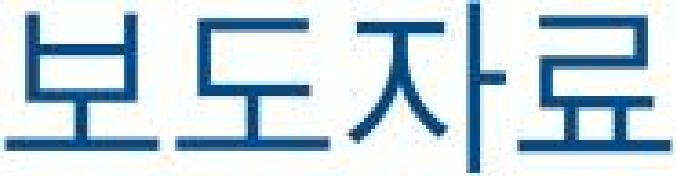

요약: 보도자료라는 글자가 적힌 이미지입니다.

이미지 번호 2 / 파일 이름: figure-1-2.jpg


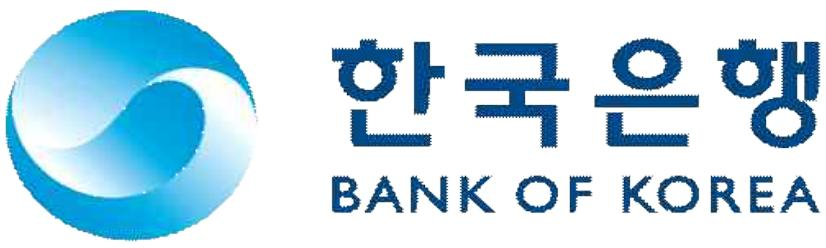

요약: 한국은행 로고, 파란색과 흰색 조화, 한글과 영어 텍스트 포함.

이미지 번호 3 / 파일 이름: figure-10-20.jpg


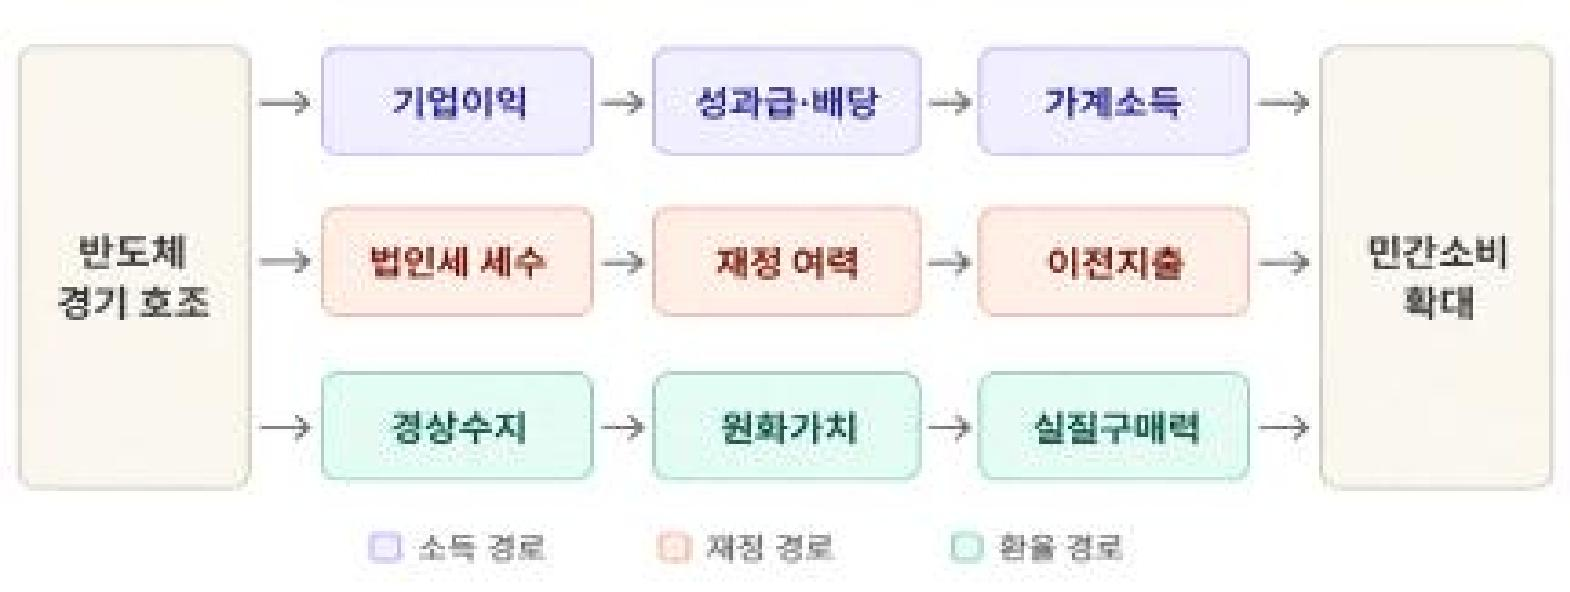

요약: 기업아이디어, 성과금-배당, 가계소득, 법인세 세수, 재정여력, 이전지출, 정상수치, 원화가치, 실질구매력 등 다양한 경제적 요소 간의 관계를 나타낸 흐름도.

이미지 번호 4 / 파일 이름: figure-10-21.jpg


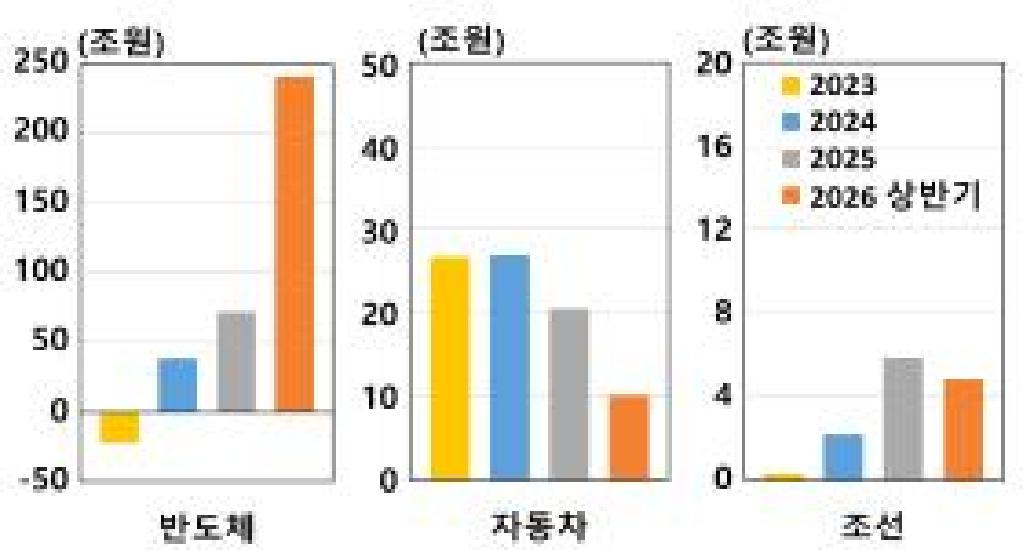

요약: 2023년, 2024년, 2025년, 2026년 상반기 데이터가 포함된 세 개의 막대 그래프. 좌측: 반도체 수치, 중앙: 자동차 수치, 우측: 조선 수치. 각 그래프는 연도별로 비교할 수 있는 정보를 제공.

이미지 번호 5 / 파일 이름: figure-10-22.jpg


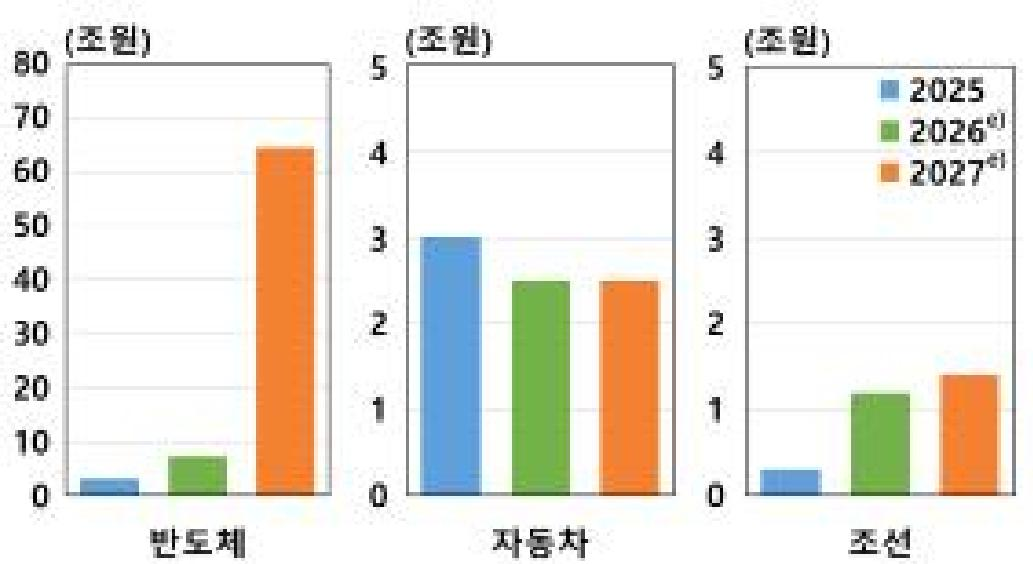

요약: 2025, 2026, 2027년의 반도체, 자동차, 조선 분야에 대한 데이터 비교 그래프. 반도체 분야는 2027년에 가장 높은 수치, 자동차와 조선은 상대적으로 낮은 수치.



In [46]:
# ⌨️ 9-1. IPython.display 에서 Image, display 를 임포트합니다.

from IPython.display import Image, display

# ⌨️ 9-2. image_files 와 image_summaries 의 앞 3개를 zip + enumerate 로 반복하며
#        구분선, 번호와 파일 이름, 이미지(width=450), 요약문을 차례로 출력합니다.

for i, (img_file, summary) in enumerate(zip(image_files[:5], image_summaries[:5])):
    print("="*60)
    print(f"이미지 번호 {i+1} / 파일 이름: {img_file.name}")
    print("="*60)
    display(Image(filename=str(img_file), width=450))
    print("요약:", summary)
    print()

**🗒️ 정리해 보기 (더블클릭해서 편집)**

- 내 요약의 수준 (나쁨 / 보통 / 좋음): 좋음
- 그렇게 판단한 이유: 텍스트/색상/범례/연도 등의 특징을 상세하게 표현하고 있다. 특히 그래프의 경우 수치 해석까지 하여 요약 검색에 유리하다.
- 개선하려면 프롬프트에 무엇을 추가할까: 개선하려면 그래프 이미지의 경우 범례/축 제목/축 간격/단위 등을 포함해서 요약하라고 지시하면 된다. 표 이미지의 경우에도 마찬가지로 단위, 연도, 증감 등을 요약하라고 지시하면 된다.

> 💡 품질이 나쁘면 프롬프트에 **"축 이름, 수치 범위, 추세를 반드시 포함하세요"** 같은 지시를 추가해 보세요.

---
# Part 4. 마무리

## 10. 토큰 사용량 측정

### 📖 개념
- `tiktoken` = OpenAI 모델이 글자를 자르는 방식(토큰화)을 로컬에서 그대로 재현하는 도구
- **실제 비용 = 토큰 수 × 단가** (단가는 OpenAI 공식 가격 페이지에서 확인)
- 이미지 토큰은 해상도에 따라 달라 이 계산에 포함되지 않습니다.

In [50]:
# ⌨️ 10-1. tiktoken 을 임포트하고 "gpt-4o-mini" 용 인코더(enc)를 가져옵니다.

# ⌨️ 10-2. texts_2k_token 전체의 토큰 수 합 → input_tokens

# ⌨️ 10-3. text_summaries 전체의 토큰 수 합 → output_tokens

# ⌨️ 10-4. 입력 / 출력 / 합계 토큰(천 단위 콤마)과 요약한 이미지 수를 출력합니다.

import tiktoken

enc = tiktoken.encoding_for_model("gpt-4o-mini")

input_tokens = sum(len(enc.encode(t)) for t in texts_2k_token)
output_tokens = sum(len(enc.encode(s)) for s in text_summaries)

print("텍스트 요약 토큰 사용량 (추정)")
print(f"입력   : {input_tokens:,} 토큰")
print(f"출력   : {output_tokens:,} 토큰")
print(f"합계   : {input_tokens + output_tokens:,} 토큰")
print()
print("요약한 이미지 수:", len(image_summaries), "장")
print()
print("※ 실제 비용 = 토큰 수 x 단가. 단가는 OpenAI 공식 가격 페이지에서 확인하세요.")
print("※ 이미지 토큰은 해상도에 따라 달라지므로 위 수치에 포함되지 않았습니다.")

텍스트 요약 토큰 사용량 (추정)
입력   : 13,512 토큰
출력   : 4,851 토큰
합계   : 18,363 토큰

요약한 이미지 수: 41 장

※ 실제 비용 = 토큰 수 x 단가. 단가는 OpenAI 공식 가격 페이지에서 확인하세요.
※ 이미지 토큰은 해상도에 따라 달라지므로 위 수치에 포함되지 않았습니다.


## 11. 저장

### 📖 개념
요약 생성에도 **API 비용과 시간**이 듭니다. 다음 시간(벡터 저장소 구축)에서 바로 불러 쓰도록 저장합니다.

In [ ]:
# ⌨️ 11-1. PROJECT_ROOT / "data" / "processed" 를 output_dir 로 잡고 폴더를 만듭니다. (parents, exist_ok)

# ⌨️ 11-2. output_dir / "summaries.pkl" 에 아래 4개 키를 가진 딕셔너리를 pickle.dump 합니다.
#         text_summaries, table_summaries, image_summaries, img_base64_list

# ⌨️ 11-3. 저장 경로를 출력합니다.

output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

# "wb" : 바이너리 파일로 저장

with open(output_dir / "summaries.pkl", "wb") as f:
    pickle.dump(
        {
            "text_summaries": text_summaries, 
            "table_summaries": table_summaries, 
            "image_summaries": image_summaries, 
            "img_base64_list": img_base64_list 
        },
        f,
    )
    
print("저장 완료:", output_dir / "summaries.pkl")
print("7교시에서 extracted.pkl 과 summaries.pkl 을 함께 불러옵니다.")

저장 완료: c:\workspaces\multimodal-rag\data\processed\summaries.pkl
7교시에서 extracted.pkl 과 summaries.pkl 을 함께 불러옵니다.


---

## ✅ 오늘의 체크포인트

- [v] `text_summaries[0]`에 한국어 요약문이 출력된다
- [v] `image_summaries[0]`에 그림을 설명하는 한국어 문장이 출력된다
- [v] 그림과 요약문을 나란히 놓고 **육안으로 검증**했다
- [v] `table_summaries`가 비어도 그 이유를 설명할 수 있다
- [v] `data/processed/summaries.pkl` 파일이 생성되었다

## 💬 생각해 볼 질문 (더블클릭해서 편집)

**Q1. 이미지를 왜 굳이 텍스트로 요약할까요? 이미지 그대로 검색하면 안 되나요?**

답: 이미지 그 자체로 LLM이 검색할 수 없기 때문에, LLM이 인식할 수 있는 이미지에 대한 요약 텍스트, 메타데이터, 의미 구조 등을 생성하여 LLM이 이미지를 검색할 수 있게 해야 한다.

**Q2. 요약문만 저장하고 원본은 버리면 어떤 문제가 생길까요?**

답: 요약문은 검색을 위한 검색 인덱스의 역할을 하기 때문에, 검색을 해도 이미지나 표의 원본을 읽어낼 수 없다.

**Q3. `max_concurrency`를 100으로 올리면 어떤 일이 벌어질까요?**

답: LLM은 동시 처리 가능한 작업 수에 제한이 있기 때문에, max_concurrency=100을 설정하면, 작업 수로 인해 부하가 생겨 RateLimitError가 발생한다.

## 🛠️ 자주 나는 에러

| 증상 | 원인 | 해결 |
| --- | --- | --- |
| `AuthenticationError` | `.env` 키 오타 / `load_dotenv()` 누락 | 키 앞뒤 공백·따옴표 제거 |
| `404 model not found` | 지원 종료된 모델명 사용 | `gpt-4o-mini` 사용 |
| `RateLimitError` | 동시 요청 과다 | `max_concurrency`를 5 → 2로 낮추기 |
| `FileNotFoundError: extracted.pkl` | 지난 시간 저장 셀 미실행 | 지난 노트북 마지막 셀 재실행 |
| `IndexError: list index out of range` | `figures/`에 이미지가 없음 | 1번 셀의 `figures_dir` 경로 확인 |
| 요약이 영어로 나옴 | 프롬프트에 한국어 지시 누락 | 프롬프트 마지막 줄 확인 |
| `NameError` | 앞 셀을 안 돌림 | 위에서부터 순서대로 재실행 |

> 그래도 안 되면 **커널 재시작 후 위에서부터 전체 재실행**하세요.

## ⏭️ 다음 시간 예고
오늘 만든 요약문을 **임베딩해 벡터 저장소(Chroma)에 넣고**, 요약으로 검색해 **원본**을 돌려주는 **멀티 벡터 검색기**를 만듭니다.